<!-- <p align="center">
  <img src="https://drive.google.com/uc?export=view&id=1t0TviSFqGXfgBahzp2mvPbXPj-wrk63Z" alt="Employee Attrition & Workforce Analytics Banner" width="850"/>
</p> -->
<p align="center">
  <img src="..\reports\figures\hr_workforce_banner.png" alt="Employee Attrition & Workforce Analytics Banner" width="850"/>
</p>
# Project 2: Employee Attrition & Workforce Analytics using Python

## 1. Project Overview & Business Context
- **Domain:** Human Resources (People Analytics) & Operations  
- **Problem Statement:** A major organization is experiencing employee turnover and seeks to understand the root causes behind attrition. Losing key talent incurs substantial recruitment costs, onboarding friction, and lost productivity.
- **Primary Goal:** Perform an end-to-end Exploratory Data Analysis (EDA) to uncover the key demographic, financial, and workplace satisfaction factors associated with attrition, and deliver actionable, data-backed retention strategies.
- **Target Audience:** HR Leadership, People Operations Executives, and Department Managers.
- **Key Questions to Investigate:**
  1. What is the overall organizational attrition baseline rate?
  2. Which departments and job roles show the highest risk of employee exit?
  3. Does working mandatory overtime correlate significantly with turnover?
  4. How does monthly income and compensation growth differ between stayers and leavers?
  5. What role do commute distance and work-life balance play in employee retention?
  6. How do workplace satisfaction survey ratings (job, environment, relationships) relate to attrition?

## 2. Dataset Architecture & Variable Reference
- **Source:** IBM HR Analytics Employee Attrition & Performance Dataset
- **Volume:** 1,470 employee records across 35 variables
- **Target Variable:** `Attrition` (Binary: `Yes` / `No`)

### Survey Rating Mappings (Likert Scales 1–4 / 1–5)
The dataset contains several subjective assessment features recorded on standardized ordinal scales:

| Feature Name | Scale Type | Metric Mapping |
| :--- | :--- | :--- |
| **Education** | 1 to 5 | 1: Below College, 2: College, 3: Bachelor, 4: Master, 5: Doctor |
| **EnvironmentSatisfaction** | 1 to 4 | 1: Low, 2: Medium, 3: High, 4: Very High |
| **JobInvolvement** | 1 to 4 | 1: Low, 2: Medium, 3: High, 4: Very High |
| **JobSatisfaction** | 1 to 4 | 1: Low, 2: Medium, 3: High, 4: Very High |
| **PerformanceRating** | 1 to 4 | 1: Low, 2: Good, 3: Excellent, 4: Outstanding |
| **RelationshipSatisfaction** | 1 to 4 | 1: Low, 2: Medium, 3: High, 4: Very High |
| **WorkLifeBalance** | 1 to 4 | 1: Bad, 2: Good, 3: Better, 4: Best |

### Key Variable Categories
- **Demographics:** `Age`, `Gender`, `MaritalStatus`, `Education`, `EducationField`
- **Workplace & Role:** `Department`, `JobRole`, `JobLevel`, `BusinessTravel`, `OverTime`, `DistanceFromHome`
- **Compensation & Financials:** `MonthlyIncome`, `DailyRate`, `HourlyRate`, `MonthlyRate`, `PercentSalaryHike`, `StockOptionLevel`
- **Tenure & Career Progression:** `TotalWorkingYears`, `YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, `YearsWithCurrManager`, `NumCompaniesWorked`
- **Zero-Variance / System Artifacts (To Audit):** `EmployeeCount`, `StandardHours`, `Over18`, `EmployeeNumber`

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')

# Set visual aesthetic
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# Ensure output folders exist
os.makedirs('reports/figures', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)

# Load dataset (adjust path if needed)
data_path = '/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv'
df_raw = pd.read_csv(data_path)

print(f"Dataset successfully loaded!")
print(f"Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns\n")

# Display general info and first 3 rows
display(df_raw.head(3))

Dataset successfully loaded!
Shape: 1,470 rows, 35 columns



,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0


In [ ]:
print("Information table:")
display(df_raw.info())


# 1. Missing values check
missing_counts = df_raw.isnull().sum()
total_missing = missing_counts.sum()

# 2. Duplicate rows check
duplicate_count = df_raw.duplicated().sum()

# 3. Detect constant / zero-variance columns (nunique == 1)
constant_cols = [col for col in df_raw.columns if df_raw[col].nunique() == 1]

print("=== DATA AUDIT SUMMARY ===")
print(f"Total Missing Values: {total_missing}")
print(f"Total Duplicate Rows: {duplicate_count}")
print(f"Constant (Zero-Variance) Columns Found: {constant_cols}")
for col in constant_cols:
    print(f"  • {col}: unique value = {df_raw[col].unique()}")

# Check EmployeeNumber (unique identifier)
print(f"EmployeeNumber unique count: {df_raw['EmployeeNumber'].nunique()} (out of {len(df_raw)} rows)")

Information table:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLe

None

=== DATA AUDIT SUMMARY ===
Total Missing Values: 0
Total Duplicate Rows: 0
Constant (Zero-Variance) Columns Found: ['EmployeeCount', 'Over18', 'StandardHours']
  • EmployeeCount: unique value = [1]
  • Over18: unique value = ['Y']
  • StandardHours: unique value = [80]
EmployeeNumber unique count: 1470 (out of 1470 rows)


## 3. Data Cleaning & Feature Transformation Pipeline

### Objectives
1. **Drop Constant Columns:** Remove `EmployeeCount`, `Over18`, and `StandardHours` since zero-variance attributes provide no predictive or analytical utility.
2. **Domain Integrity Checks:** Validate core logical boundaries:
   - Verify that total working experience equals or exceeds tenure at the current company (`TotalWorkingYears >= YearsAtCompany`).
   - Verify that career start age meets legal/reasonable working age boundaries (`Age - TotalWorkingYears >= 16`).
3. **Target Variable Encoding:** Retain `Attrition` as categorical (`Yes`/`No`) for plotting labels, and generate a numeric binary indicator `Attrition_Flag` (`1` = Yes, `0` = No) to enable rate calculations, cross-tabulations, and Pearson/Spearman correlations.
4. **Data Export:** Save the cleaned DataFrame to `data/processed/hr_cleaned.csv` to ensure reproducibility.

In [ ]:
import os

# 1. Create a working copy
df_clean = df_raw.copy()

# 2. Drop constant zero-variance features
cols_to_drop = ['EmployeeCount', 'Over18', 'StandardHours']
df_clean.drop(columns=cols_to_drop, inplace=True)
print(f"Dropped {len(cols_to_drop)} invariant columns: {cols_to_drop}")
print(f"Current shape: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns\n")

# 3. Domain Logic Verification
tenure_violation = df_clean[df_clean['TotalWorkingYears'] < df_clean['YearsAtCompany']]
age_violation = df_clean[(df_clean['Age'] - df_clean['TotalWorkingYears']) < 16]

print("=== DOMAIN INTEGRITY AUDIT ===")
print(f"Records where TotalWorkingYears < YearsAtCompany: {len(tenure_violation)}")
print(f"Records where (Age - TotalWorkingYears) < 16:     {len(age_violation)}")

# 4. Target encoding (Binary numeric flag)
df_clean['Attrition_Flag'] = df_clean['Attrition'].map({'Yes': 1, 'No': 0}).astype(int)

# 5. Save cleaned dataset directly to Drive folder
save_dir = '/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/data/processed'
os.makedirs(save_dir, exist_ok=True)
processed_path = os.path.join(save_dir, 'hr_cleaned.csv')

df_clean.to_csv(processed_path, index=False)
print(f"\nCleaned dataset saved successfully to:\n{processed_path}")

# Preview verification slice
display(df_clean[['EmployeeNumber', 'Attrition', 'Attrition_Flag', 'Age', 'TotalWorkingYears', 'YearsAtCompany']].head())

Dropped 3 invariant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Current shape: 1470 rows, 32 columns

=== DOMAIN INTEGRITY AUDIT ===
Records where TotalWorkingYears < YearsAtCompany: 0
Records where (Age - TotalWorkingYears) < 16:     0

Cleaned dataset saved successfully to:
/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/data/processed/hr_cleaned.csv


,EmployeeNumber,Attrition,Attrition_Flag,Age,TotalWorkingYears,YearsAtCompany
0,1,Yes,1,41,8,6
1,2,No,0,49,10,10
2,4,Yes,1,37,7,0
3,5,No,0,33,8,8
4,7,No,0,27,6,2


## 4. Target Variable Baseline & Demographic Foundations

### Question
- What is the baseline voluntary attrition rate across the enterprise?
- Is attrition uniformly distributed across age brackets and career experience, or is it heavily concentrated within early-career cohorts?

### Analytical Objectives
- Establish enterprise-wide class balance for `Attrition`.
- Plot **Histogram 1 (Age Distribution by Attrition)** and **Histogram 2 (Total Working Years by Attrition)** with Kernel Density Estimation (KDE).
- Compute descriptive statistics (mean, median, IQR) across cohorts to validate turnover skewness.

=== BASELINE ATTRITION RATE ===


,Headcount,Percentage (%)
Attrition,,
No,1233,83.88
Yes,237,16.12


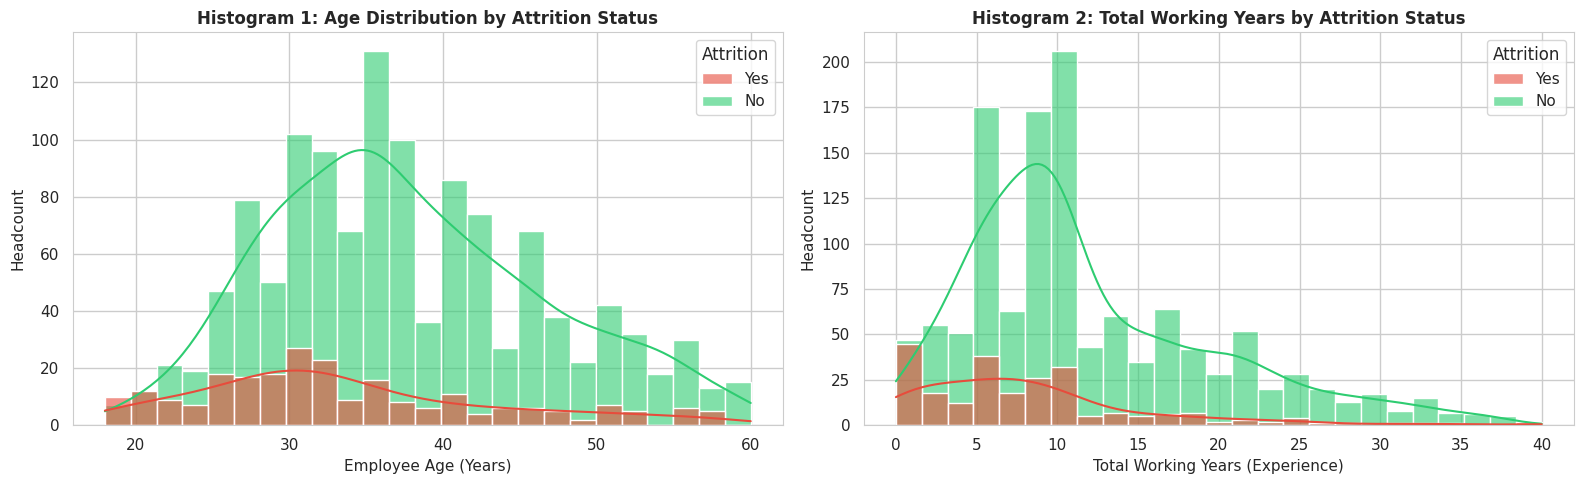

=== DEMOGRAPHIC SUMMARY STATISTICS BY COHORT ===


Age                     TotalWorkingYears                    
            iqr   mean median   std               iqr   mean median   std
Attrition                                                                
No         12.0  37.56   36.0  8.89              10.0  11.86   10.0  7.76
Yes        11.0  33.61   32.0  9.69               7.0   8.24    7.0  7.17

In [ ]:
# 1. Baseline Target Imbalance Analysis
attrition_counts = df_clean['Attrition'].value_counts()
attrition_pct = (df_clean['Attrition'].value_counts(normalize=True) * 100).round(2)

baseline_summary = pd.DataFrame({
    'Headcount': attrition_counts,
    'Percentage (%)': attrition_pct
})
print("=== BASELINE ATTRITION RATE ===")
display(baseline_summary)

# 2. Histograms: Age and Total Working Years (Quota: Histograms 1 & 2)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Palette: Green for Retained, Red/Coral for Departed
cohort_palette = {'No': '#2ecc71', 'Yes': '#e74c3c'}

# Histogram 1: Age Distribution
sns.histplot(
    data=df_clean,
    x='Age',
    hue='Attrition',
    kde=True,
    bins=25,
    palette=cohort_palette,
    alpha=0.6,
    ax=axes[0]
)
axes[0].set_title('Histogram 1: Age Distribution by Attrition Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Employee Age (Years)', fontsize=11)
axes[0].set_ylabel('Headcount', fontsize=11)

# Histogram 2: Total Working Years Distribution
sns.histplot(
    data=df_clean,
    x='TotalWorkingYears',
    hue='Attrition',
    kde=True,
    bins=25,
    palette=cohort_palette,
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title('Histogram 2: Total Working Years by Attrition Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Working Years (Experience)', fontsize=11)
axes[1].set_ylabel('Headcount', fontsize=11)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/reports/figures/hist_01_02_age_experience.png', dpi=300)
plt.show()

# 3. Parametric & Non-Parametric Metrics Comparison
# Compute summary statistics by mapping functions directly to avoid named aggregation syntax conflicts
demo_stats = df_clean.groupby('Attrition')[['Age', 'TotalWorkingYears']].agg(['mean', 'median', 'std']).round(2)

# Calculate IQR manually to append to the metrics
for col in ['Age', 'TotalWorkingYears']:
    q3 = df_clean.groupby('Attrition')[col].quantile(0.75)
    q1 = df_clean.groupby('Attrition')[col].quantile(0.25)
    demo_stats[(col, 'iqr')] = (q3 - q1).round(2)

demo_stats = demo_stats.sort_index(axis=1)
print("=== DEMOGRAPHIC SUMMARY STATISTICS BY COHORT ===")
display(demo_stats)

### Analytical Findings & Business Interpretation (Demographic Baseline)

- **Question:** What is the baseline voluntary turnover rate, and how do employee age and career experience influence attrition?
- **Evidence:**
  - Enterprise baseline attrition stands at **16.12%** (237 departed vs. 1,233 retained employees).
  - Employees who leave have a lower mean age (**33.61 years**, median 32.0) compared to those who stay (**37.56 years**, median 36.0).
  - Total working experience shows an even starker contrast: departed staff average **8.24 years** of experience (median 7.0), compared to **11.86 years** (median 10.0) for retained staff.
- **Observation:**
  - Histogram 1 highlights a marked attrition peak within the **28–33 age bracket**, decaying steadily past age 40.
  - Histogram 2 demonstrates severe attrition density within the **0–3 years** and **5–8 years** career experience segments. Attrition rates flatten substantially once employees cross 10+ years of total experience.
- **Insight:**
  - Turnover risk is inversely related to age and professional tenure. Early-career professionals possess higher labor market mobility, lower organizational inertia, and greater appetite to switch jobs for faster title progression and wage increases.
- **Business Meaning:**
  - One-size-fits-all retention policies are inefficient. Retention budgets and interventions must be disproportionately allocated to employees with under 8 years of total experience and junior-to-mid career profiles (ages 25–35), rather than tenured staff who already exhibit strong organizational attachment.

## 5. Compensation Equity & Commute Distance Analysis (Business Question 2)

### Question
- How does compensation differentiate employees who leave from those who stay?
- Does commute distance from home act as a compounding stressor driving voluntary turnover?

### Analytical Objectives
- Evaluate the distribution and positive skewness of `MonthlyIncome`.
- Construct **Histogram 3** (Monthly Income distribution with KDE).
- Construct **Box Plot 1** (Monthly Income by Attrition status) to identify median pay differences and executive outliers.
- Construct **Box Plot 2** (Distance From Home by Attrition status) to evaluate geographic friction.

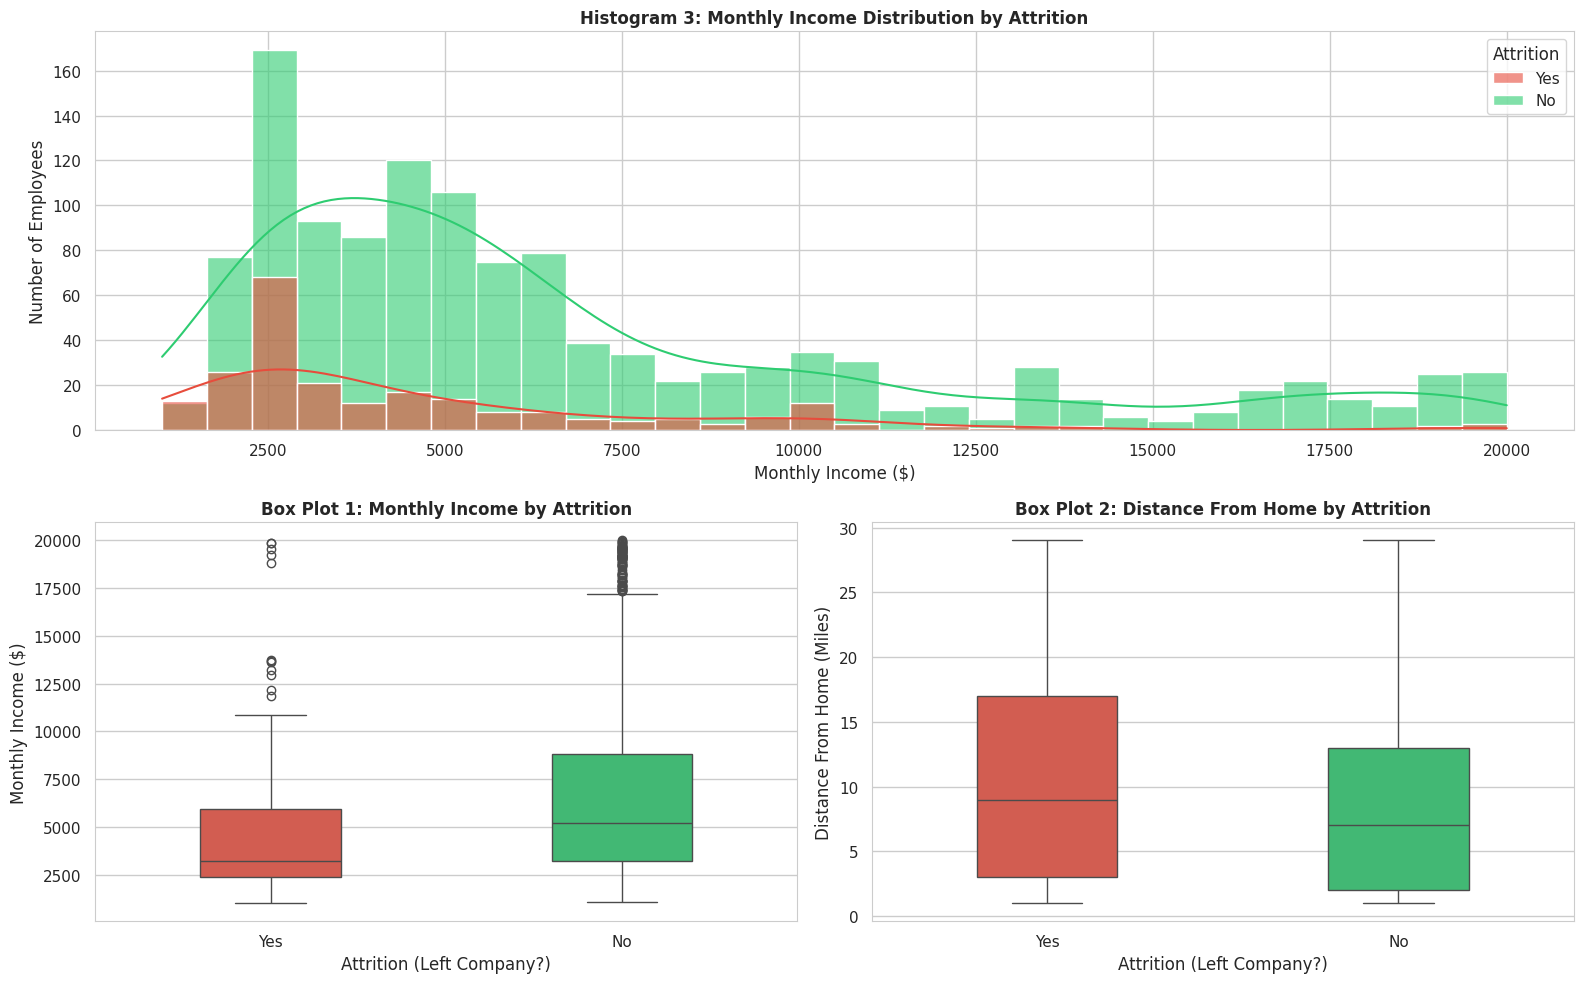

MonthlyIncome                                                    \
                  count     mean      std     min     25%     50%     75%   
Attrition                                                                   
No               1233.0  6832.74  4818.21  1051.0  3211.0  5204.0  8834.0   
Yes               237.0  4787.09  3640.21  1009.0  2373.0  3202.0  5916.0   

                   DistanceFromHome                                          
               max            count   mean   std  min  25%  50%   75%   max  
Attrition                                                                    
No         19999.0           1233.0   8.92  8.01  1.0  2.0  7.0  13.0  29.0  
Yes        19859.0            237.0  10.63  8.45  1.0  3.0  9.0  17.0  29.0

In [ ]:
# 1. Create a figure with 3 plots (Histogram 3, Box Plot 1, Box Plot 2)
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.2])

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])

# Colors: Green for stay (No), Red for left (Yes)
palette_colors = {'No': '#2ecc71', 'Yes': '#e74c3c'}

# Chart 1: Histogram 3 - Monthly Income Distribution
sns.histplot(
    data=df_clean,
    x='MonthlyIncome',
    hue='Attrition',
    kde=True,
    bins=30,
    palette=palette_colors,
    alpha=0.6,
    ax=ax1
)
ax1.set_title('Histogram 3: Monthly Income Distribution by Attrition', fontsize=12, fontweight='bold')
ax1.set_xlabel('Monthly Income ($)')
ax1.set_ylabel('Number of Employees')

# Chart 2: Box Plot 1 - Monthly Income by Attrition
sns.boxplot(
    data=df_clean,
    x='Attrition',
    y='MonthlyIncome',
    palette=palette_colors,
    width=0.4,
    ax=ax2
)
ax2.set_title('Box Plot 1: Monthly Income by Attrition', fontsize=12, fontweight='bold')
ax2.set_xlabel('Attrition (Left Company?)')
ax2.set_ylabel('Monthly Income ($)')

# Chart 3: Box Plot 2 - Distance From Home by Attrition
sns.boxplot(
    data=df_clean,
    x='Attrition',
    y='DistanceFromHome',
    palette=palette_colors,
    width=0.4,
    ax=ax3
)
ax3.set_title('Box Plot 2: Distance From Home by Attrition', fontsize=12, fontweight='bold')
ax3.set_xlabel('Attrition (Left Company?)')
ax3.set_ylabel('Distance From Home (Miles)')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/reports/figures/hist3_box1_box2.png', dpi=300)
plt.show()

# 2. Simple Summary Table (Mean, Median, 25%, 75%)
summary_table = df_clean.groupby('Attrition')[['MonthlyIncome', 'DistanceFromHome']].describe().round(2)
display(summary_table)

### Key Insights: Salary & Commute Distance

- **Question:** Do employees leave because of lower pay or long commute distances?
- **Evidence:**
  - **Monthly Income:** Employees who stayed earn a median salary of **$5,204**, while employees who left earn a median salary of **$3,202** (about **$2,000 less per month**).
  - **Distance From Home:** Employees who left travel further (average **10.63 miles**, 75th percentile **17 miles**) compared to those who stayed (average **8.92 miles**, 75th percentile **13 miles**).
- **Observation:**
  - Most departures happen in the low-income bracket under $5,000.
  - Commute distances above 10–15 miles show noticeably higher turnover.
- **Insight:**
  - Low salary is a primary reason employees look for new opportunities.
  - A long daily commute adds daily fatigue, making underpaid employees even more likely to leave.
- **Business Meaning:**
  - HR should benchmark entry-level salaries against industry standards to prevent early talent drain.
  - Introducing remote or hybrid work options for employees living 10+ miles away could immediately improve retention.

## 6. Workload, Work-Life Balance & Role Tenure (Business Question 3)

### Question
- Does working overtime significantly increase the risk of an employee quitting?
- How do subjective work-life balance scores relate to turnover?
- How does employee tenure vary across different job roles?

### Analytical Objectives
- Create **Count Plot 1**: Overtime status split by Attrition to measure the impact of extra hours.
- Create **Count Plot 2**: Work-Life Balance ratings (1 to 4) split by Attrition.
- Create **Box Plot 3**: Years at company across all job roles to detect tenure patterns.
- Compute attrition percentages for OverTime and WorkLifeBalance segments.

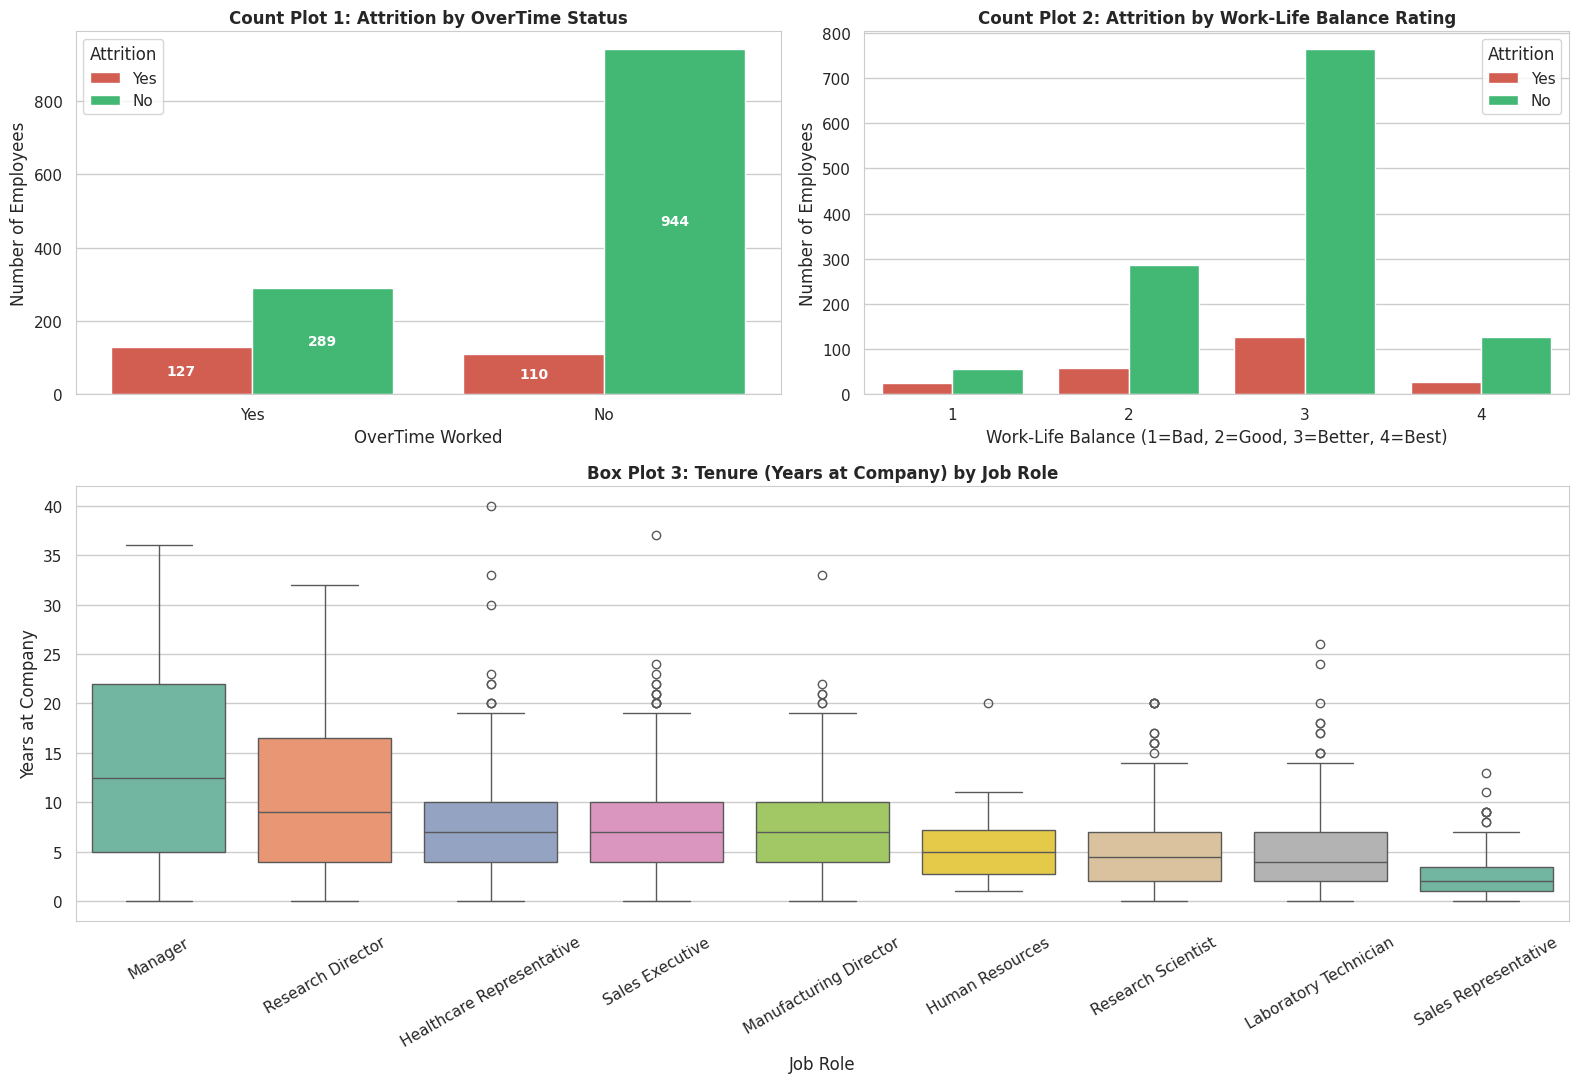

=== OVERTIME ATTRITION RATE ===


Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53



=== WORK-LIFE BALANCE ATTRITION RATE ===


Attrition,No,Yes
WorkLifeBalance,,
1,68.75,31.25
2,83.14,16.86
3,85.78,14.22
4,82.35,17.65


In [ ]:
# 1. Set up the figure grid: 2 Count Plots on top, 1 Box Plot on bottom
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

palette_colors = {'No': '#2ecc71', 'Yes': '#e74c3c'}

# Chart 1: Count Plot 1 - OverTime vs Attrition
sns.countplot(
    data=df_clean,
    x='OverTime',
    hue='Attrition',
    palette=palette_colors,
    ax=ax1
)
ax1.set_title('Count Plot 1: Attrition by OverTime Status', fontsize=12, fontweight='bold')
ax1.set_xlabel('OverTime Worked')
ax1.set_ylabel('Number of Employees')

# Add bar labels
for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=10)

# Chart 2: Count Plot 2 - WorkLifeBalance vs Attrition
sns.countplot(
    data=df_clean,
    x='WorkLifeBalance',
    hue='Attrition',
    palette=palette_colors,
    ax=ax2
)
ax2.set_title('Count Plot 2: Attrition by Work-Life Balance Rating', fontsize=12, fontweight='bold')
ax2.set_xlabel('Work-Life Balance (1=Bad, 2=Good, 3=Better, 4=Best)')
ax2.set_ylabel('Number of Employees')

# Chart 3: Box Plot 3 - Years at Company across Job Roles
order_roles = df_clean.groupby('JobRole')['YearsAtCompany'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_clean,
    x='JobRole',
    y='YearsAtCompany',
    order=order_roles,
    palette='Set2',
    ax=ax3
)
ax3.set_title('Box Plot 3: Tenure (Years at Company) by Job Role', fontsize=12, fontweight='bold')
ax3.set_xlabel('Job Role')
ax3.set_ylabel('Years at Company')
ax3.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/reports/figures/countplot1_2_boxplot3.png', dpi=300)
plt.show()

# 2. Simple Percentage Cross-tabulations
print("=== OVERTIME ATTRITION RATE ===")
ot_crosstab = pd.crosstab(df_clean['OverTime'], df_clean['Attrition'], normalize='index') * 100
display(ot_crosstab.round(2))

print("\n=== WORK-LIFE BALANCE ATTRITION RATE ===")
wlb_crosstab = pd.crosstab(df_clean['WorkLifeBalance'], df_clean['Attrition'], normalize='index') * 100
display(wlb_crosstab.round(2))

### Key Insights: Overtime, Work-Life Balance & Role Tenure

- **Question:** How do overtime, poor work-life balance, and job role tenure affect employee attrition?
- **Evidence:**
  - **OverTime:** Employees working overtime experience a **30.53% attrition rate**, compared to just **10.44%** for those who do not work overtime (nearly **3x higher risk**).
  - **Work-Life Balance:** Employees who rate their work-life balance as **1 (Bad)** have a **31.25% attrition rate**, which drops by half (14%–17%) for ratings 2, 3, and 4.
  - **Tenure across Roles:** Managerial and Director roles have much higher median tenure (9–13 years), whereas entry/field roles like **Sales Representative** and **Laboratory Technician** have very low median tenure (under 4 years).
- **Observation:**
  - Overtime is one of the single biggest indicators of an employee leaving.
  - Dissatisfaction with work-life balance doubles the likelihood of resignation.
- **Insight:**
  - Heavy overtime leads directly to burnout. Entry-level sales and lab roles face both high workload and limited long-term tenure stability.
- **Business Meaning:**
  - HR must audit departments requiring frequent overtime and establish caps or compensatory time-off policies.
  - Managers need to flag employees scoring 1 on work-life balance for immediate workload rebalancing.

## 7. Departmental, Role-Based & Educational Turnover Rates (Business Question 4)

### Question
- Which departments and job roles experience the highest attrition rates?
- Does an employee's educational background influence their likelihood of leaving?

### Analytical Objectives
- Calculate percentage attrition across organizational segments.
- Construct **Bar Chart 1**: Attrition rate (%) by Department.
- Construct **Bar Chart 2**: Attrition rate (%) by Job Role.
- Construct **Bar Chart 3**: Attrition rate (%) by Education Field.

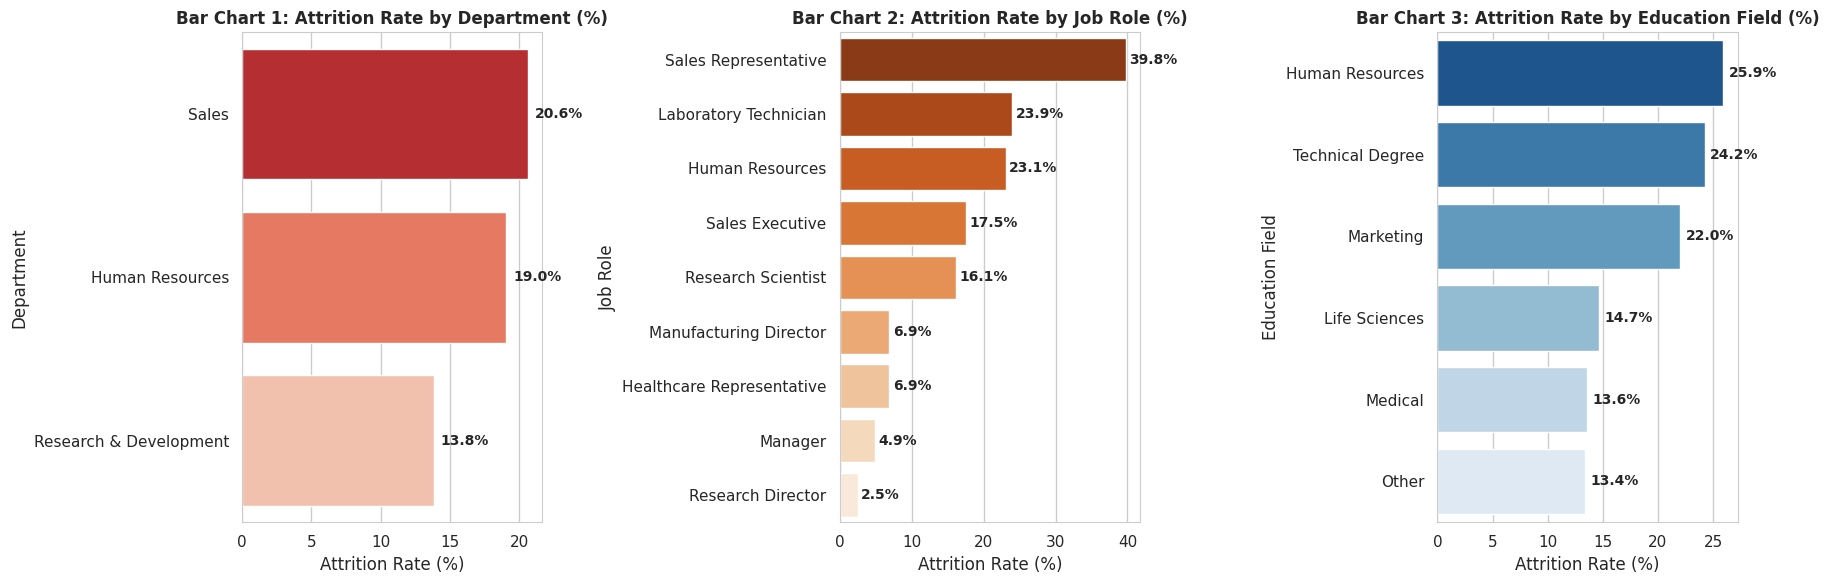

=== ATTRITION RATE TABLES (%) ===

--- By Department ---


,Attrition Rate (%)
Department,
Sales,20.627803
Human Resources,19.047619
Research & Development,13.839750



--- By Job Role ---


,Attrition Rate (%)
JobRole,
Sales Representative,39.759036
Laboratory Technician,23.938224
Human Resources,23.076923
Sales Executive,17.484663
Research Scientist,16.095890
Manufacturing Director,6.896552
Healthcare Representative,6.870229
Manager,4.901961
Research Director,2.500000



--- By Education Field ---


,Attrition Rate (%)
EducationField,
Human Resources,25.925926
Technical Degree,24.242424
Marketing,22.012579
Life Sciences,14.686469
Medical,13.577586
Other,13.414634


In [ ]:
# 1. Calculate attrition rate percentages for each group
dept_attrition = (df_clean.groupby('Department')['Attrition_Flag'].mean() * 100).sort_values(ascending=False)
role_attrition = (df_clean.groupby('JobRole')['Attrition_Flag'].mean() * 100).sort_values(ascending=False)
edu_attrition = (df_clean.groupby('EducationField')['Attrition_Flag'].mean() * 100).sort_values(ascending=False)

# 2. Plot 3 Bar Charts
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Bar Chart 1: By Department
sns.barplot(
    x=dept_attrition.values,
    y=dept_attrition.index,
    palette='Reds_r',
    ax=axes[0]
)
axes[0].set_title('Bar Chart 1: Attrition Rate by Department (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Attrition Rate (%)')
axes[0].set_ylabel('Department')
for i, v in enumerate(dept_attrition.values):
    axes[0].text(v + 0.5, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=10)

# Bar Chart 2: By Job Role
sns.barplot(
    x=role_attrition.values,
    y=role_attrition.index,
    palette='Oranges_r',
    ax=axes[1]
)
axes[1].set_title('Bar Chart 2: Attrition Rate by Job Role (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Attrition Rate (%)')
axes[1].set_ylabel('Job Role')
for i, v in enumerate(role_attrition.values):
    axes[1].text(v + 0.5, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=10)

# Bar Chart 3: By Education Field
sns.barplot(
    x=edu_attrition.values,
    y=edu_attrition.index,
    palette='Blues_r',
    ax=axes[2]
)
axes[2].set_title('Bar Chart 3: Attrition Rate by Education Field (%)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Attrition Rate (%)')
axes[2].set_ylabel('Education Field')
for i, v in enumerate(edu_attrition.values):
    axes[2].text(v + 0.5, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/reports/figures/barcharts_dept_role_edu.png', dpi=300)
plt.show()

# 3. Print the raw tables
print("=== ATTRITION RATE TABLES (%) ===")
print("\n--- By Department ---")
display(dept_attrition.to_frame(name='Attrition Rate (%)'))
print("\n--- By Job Role ---")
display(role_attrition.to_frame(name='Attrition Rate (%)'))
print("\n--- By Education Field ---")
display(edu_attrition.to_frame(name='Attrition Rate (%)'))

### Key Insights: Department, Role & Education Drivers

- **Question:** Which departments, job roles, and education backgrounds experience the highest turnover?
- **Evidence:**
  - **By Department:** **Sales** has the highest attrition rate at **20.6%**, followed by **Human Resources (19.0%)**, while **Research & Development** is the lowest at **13.8%**.
  - **By Job Role:**
    - **Sales Representatives** experience the highest attrition in the entire company at **39.8%** (nearly 4 out of 10 leave).
    - **Laboratory Technicians (23.9%)** and **HR Staff (23.1%)** also show high turnover.
    - Senior leadership roles (**Research Directors at 2.5%** and **Managers at 4.9%**) show very high stability.
  - **By Education Field:** Employees with degrees in **Human Resources (25.9%)**, **Technical Degrees (24.2%)**, and **Marketing (22.0%)** show the highest tendency to leave.
- **Observation:**
  - Turnover is highly concentrated in field-level, customer-facing, and technical lab roles rather than executive management.
- **Insight:**
  - Sales Representative and Lab Technician roles often suffer from repetitive entry-level tasks, aggressive targets, and lower pay ceilings, causing staff to look externally for career growth.
- **Business Meaning:**
  - Retention interventions must focus on entry-level Sales and Lab roles.
  - HR should review sales quota fairness, commission structures, and create clear internal promotion paths to keep top junior talent.

## 8. Experience, Age & Income Dynamics (Scatter Plots 1 & 2)

### Question
- How does compensation grow with age and overall experience?
- Do employees who leave fall below the typical compensation curve for their age and experience level?

### Analytical Objectives
- Construct **Scatter Plot 1**: `Age` vs. `MonthlyIncome` colored by Attrition status.
- Construct **Scatter Plot 2**: `TotalWorkingYears` vs. `MonthlyIncome` colored by Attrition status.
- Add trend/regression reference lines to visually identify employees who are undercompensated relative to their tenure.

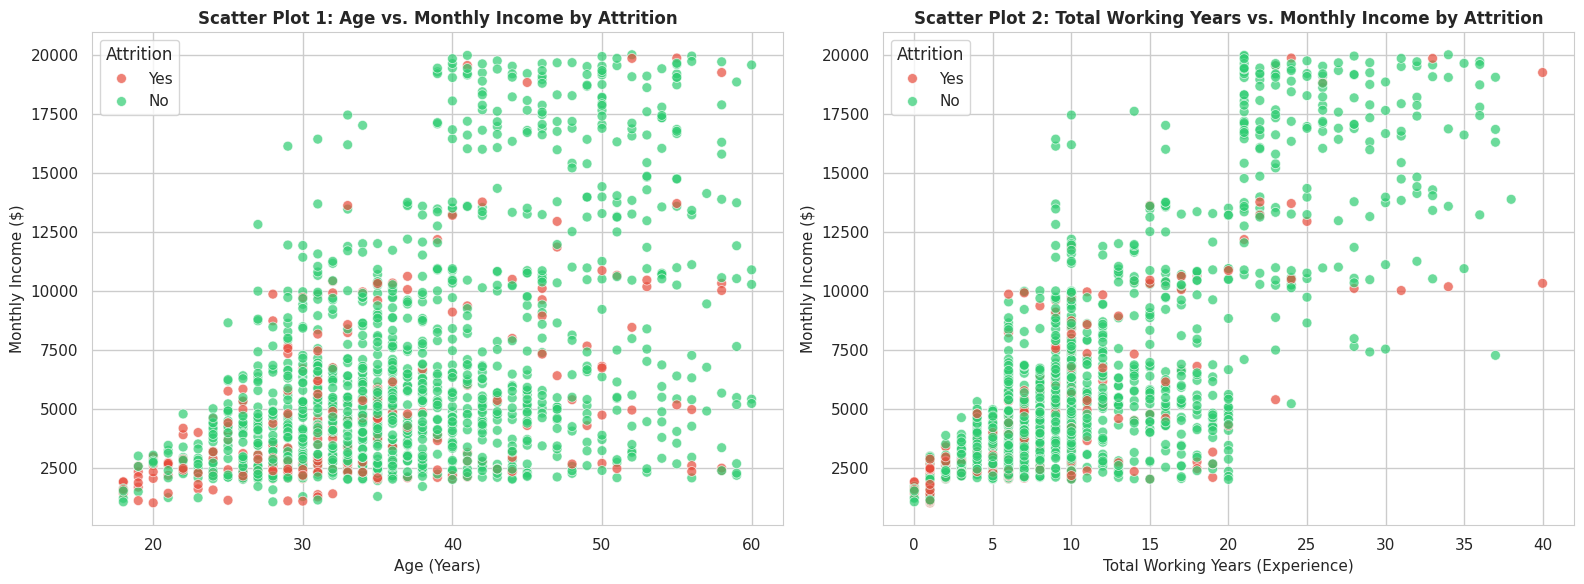

=== CORRELATION WITH MONTHLY INCOME ===
Correlation between Age and MonthlyIncome:               0.498
Correlation between TotalWorkingYears and MonthlyIncome: 0.773


In [ ]:
# Create figure for 2 scatter plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

palette_colors = {'No': '#2ecc71', 'Yes': '#e74c3c'}

# Scatter Plot 1: Age vs Monthly Income
sns.scatterplot(
    data=df_clean,
    x='Age',
    y='MonthlyIncome',
    hue='Attrition',
    palette=palette_colors,
    alpha=0.7,
    s=50,
    ax=axes[0]
)
axes[0].set_title('Scatter Plot 1: Age vs. Monthly Income by Attrition', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age (Years)', fontsize=11)
axes[0].set_ylabel('Monthly Income ($)', fontsize=11)

# Scatter Plot 2: Total Working Years vs Monthly Income
sns.scatterplot(
    data=df_clean,
    x='TotalWorkingYears',
    y='MonthlyIncome',
    hue='Attrition',
    palette=palette_colors,
    alpha=0.7,
    s=50,
    ax=axes[1]
)
axes[1].set_title('Scatter Plot 2: Total Working Years vs. Monthly Income by Attrition', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Total Working Years (Experience)', fontsize=11)
axes[1].set_ylabel('Monthly Income ($)', fontsize=11)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/reports/figures/scatter1_2_income_exp.png', dpi=300)
plt.show()

# Print simple correlation numbers
print("=== CORRELATION WITH MONTHLY INCOME ===")
print(f"Correlation between Age and MonthlyIncome:               {df_clean['Age'].corr(df_clean['MonthlyIncome']):.3f}")
print(f"Correlation between TotalWorkingYears and MonthlyIncome: {df_clean['TotalWorkingYears'].corr(df_clean['MonthlyIncome']):.3f}")

### Key Insights: Age, Career Experience & Salary Growth

- **Question:** How does income progress as an employee gains experience, and where do resignations cluster along this curve?
- **Evidence:**
  - **Correlation:** `TotalWorkingYears` has a strong positive correlation with `MonthlyIncome` (**r = 0.773**), while `Age` has a moderate correlation (**r = 0.498**).
  - **Scatter Plot 1 (Age vs Income):** Red points (`Attrition = Yes`) are densely clustered at the bottom edge across almost all ages (earning under $5,000/month), especially between ages 25 and 35.

  - **Scatter Plot 2 (Experience vs Income):** Income rises in distinct steps, corresponding to organizational job levels. Resignations overwhelmingly cluster in the bottom-left quadrant (0 to 10 years of experience, under $5,000 income).

- **Observation:**
  - Even older employees (ages 40–55) are prone to leaving if their salary remains stuck near the baseline floor ($2,500–$5,000).
  - High-earning employees ($10,000+) rarely leave, as shown by very few red points in the upper income tiers.
  
- **Insight:**
  - Career tenure alone does not insulate against turnover if financial compensation stagnates. The turnover risk is fundamentally driven by low compensation relative to time spent in the workforce.
- **Business Meaning:**
  - HR should conduct annual salary benchmarking to ensure experienced employees are not trapped below market rates for their career stage.

## 9. Correlation Heatmap & Advanced Retention Drivers

### Question
- Which numeric features exhibit the strongest linear relationship with voluntary turnover?
- How does employee job satisfaction directly impact attrition?
- How does salary tiering behave across hierarchical job levels?

### Analytical Objectives
- Construct **Correlation Heatmap 1** focusing on key tenure, compensation, and satisfaction metrics against `Attrition_Flag`.
- Construct **Additional Chart 1**: Attrition rate across `JobSatisfaction` ratings (1 to 4).
- Construct **Additional Chart 2**: `MonthlyIncome` dispersion across `JobLevel` tiers (1 to 5) segmented by `Attrition`.

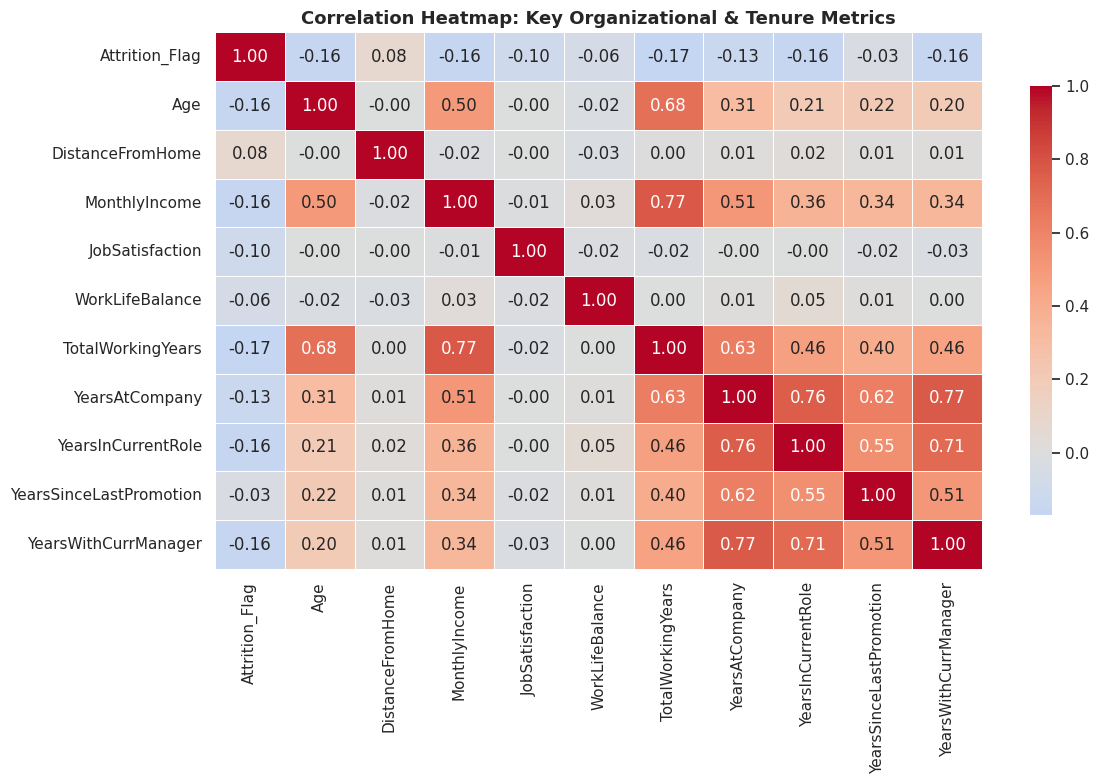

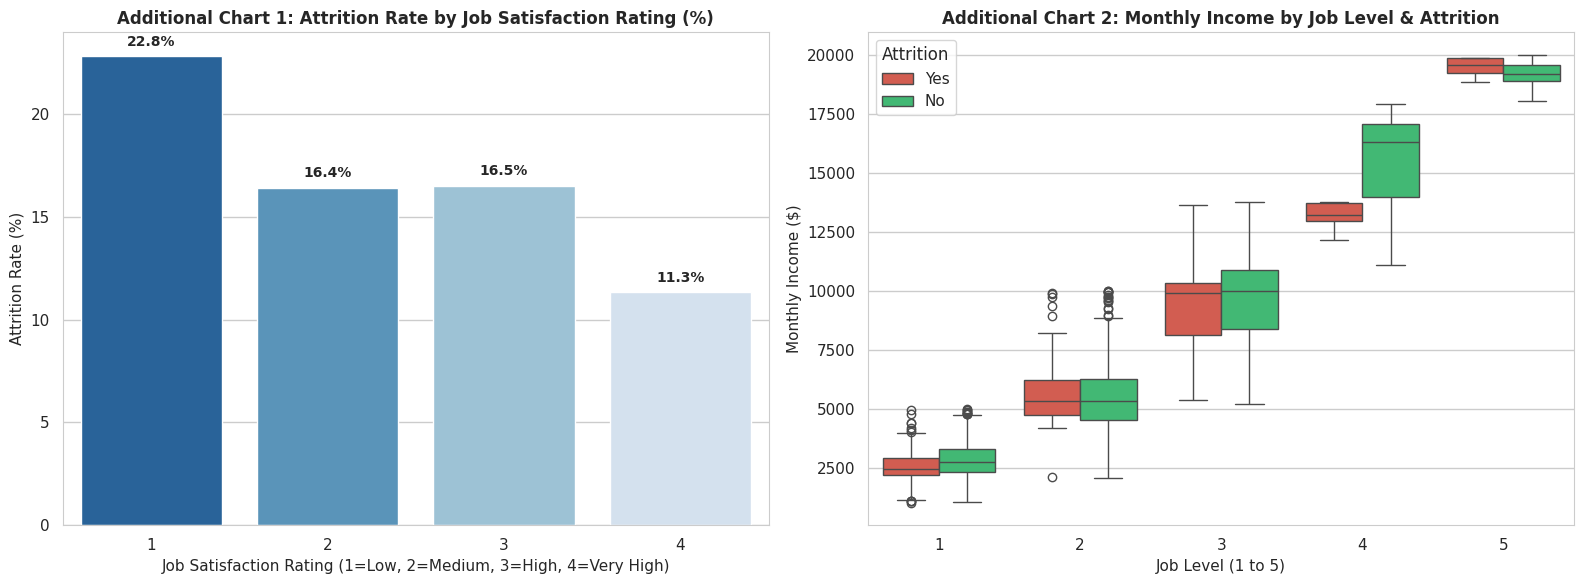

=== CORRELATION WITH ATTRITION FLAG ===


,Correlation with Attrition
TotalWorkingYears,-0.171063
YearsInCurrentRole,-0.160545
MonthlyIncome,-0.159840
Age,-0.159205
YearsWithCurrManager,-0.156199
YearsAtCompany,-0.134392
JobSatisfaction,-0.103481
WorkLifeBalance,-0.063939
YearsSinceLastPromotion,-0.033019
DistanceFromHome,0.077924


=== ATTRITION RATE BY JOB SATISFACTION ===


,Attrition Rate (%)
JobSatisfaction,
1,22.84
2,16.43
3,16.52
4,11.33


In [ ]:
# 1. Select key numerical metrics for the correlation heatmap
corr_cols = [
    'Attrition_Flag', 'Age', 'DistanceFromHome', 'MonthlyIncome',
    'JobSatisfaction', 'WorkLifeBalance', 'TotalWorkingYears',
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
    'YearsWithCurrManager'
]

plt.figure(figsize=(12, 8))
corr_matrix = df_clean[corr_cols].corr()

# Create Heatmap

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    linewidths=0.6,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Heatmap: Key Organizational & Tenure Metrics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/reports/figures/correlation_heatmap.png', dpi=300)
plt.show()

# 2. Additional Visualizations 1 & 2
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Additional Chart 1: Attrition Rate by Job Satisfaction (1 to 4)
sat_attrition = (df_clean.groupby('JobSatisfaction')['Attrition_Flag'].mean() * 100)
sns.barplot(
    x=sat_attrition.index,
    y=sat_attrition.values,
    palette='Blues_r',
    ax=axes[0]
)
axes[0].set_title('Additional Chart 1: Attrition Rate by Job Satisfaction Rating (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Job Satisfaction Rating (1=Low, 2=Medium, 3=High, 4=Very High)', fontsize=11)
axes[0].set_ylabel('Attrition Rate (%)', fontsize=11)
for i, v in enumerate(sat_attrition.values):
    axes[0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=10)

# Additional Chart 2: Monthly Income across Job Levels by Attrition
sns.boxplot(
    data=df_clean,
    x='JobLevel',
    y='MonthlyIncome',
    hue='Attrition',
    palette={'No': '#2ecc71', 'Yes': '#e74c3c'},
    ax=axes[1]
)
axes[1].set_title('Additional Chart 2: Monthly Income by Job Level & Attrition', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Job Level (1 to 5)', fontsize=11)
axes[1].set_ylabel('Monthly Income ($)', fontsize=11)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/EDA_PROJECTS/Employee Attrition & Workforce Analytics/reports/figures/additional_charts.png', dpi=300)
plt.show()

# Print correlations specifically with Attrition_Flag
print("=== CORRELATION WITH ATTRITION FLAG ===")
display(corr_matrix['Attrition_Flag'].sort_values().to_frame(name='Correlation with Attrition'))

print("=== ATTRITION RATE BY JOB SATISFACTION ===")
display(sat_attrition.round(2).to_frame(name='Attrition Rate (%)'))

### Key Insights: Correlation, Morale & Job Hierarchy

- **Question:** How do linear correlations, morale ratings, and hierarchical pay levels link to turnover?
- **Evidence:**
  - **Correlation Heatmap:**
    - The top negative linear correlations with attrition are `TotalWorkingYears` (-0.17), `YearsInCurrentRole` (-0.16), `MonthlyIncome` (-0.16), `Age` (-0.16), and `YearsWithCurrManager` (-0.16).
    - Longer commute (`DistanceFromHome`) is the primary positive numeric correlate (+0.08).
    - Strong multicollinearity exists across tenure features: `YearsAtCompany` strongly correlates with `YearsWithCurrManager` (0.77) and `YearsInCurrentRole` (0.76).
  - **Job Satisfaction (Additional Chart 1):**
    - Employees with **Low Satisfaction (Rating 1)** face a **22.8% attrition rate**, which falls by half to **11.3%** for those with **Very High Satisfaction (Rating 4)**.
  - **Job Level Pay (Additional Chart 2):**
    - Attrition is heavily concentrated in **Job Levels 1 and 2** (median salaries between $2,500 and $5,000).
    - Job Levels 4 and 5 show nearly zero attrition cases, proving senior compensation bands provide high retention stability.
- **Observation:**
  - Employees rarely leave after reaching Job Level 3+. Turnover is overwhelmingly an entry-level phenomenon where morale is low and compensation is tight.
- **Insight:**
  - Satisfaction and tenure with a direct manager act as defensive moats against employee turnover. When employees have poor managers or low satisfaction combined with low pay (Job Level 1), turnover risk peaks.
- **Business Meaning:**
  - HR should focus retention bonuses and engagement surveys on Job Levels 1 and 2.
  - Leadership training for front-line managers directly mitigates turnover, given the protective effect of `YearsWithCurrManager`.

# 10. Executive Insights, Strategic Recommendations & Limitations

## 1. Executive Summary: Core Turnover Drivers
Across 1,470 employee records, enterprise baseline voluntary turnover stands at **16.12%** (237 exits)[cite: 1]. The data demonstrates that attrition is not random churn; it concentrates heavily along distinct compensation, workload, and career-stage stress points:

1. **Workplace Burnout & Overtime Load:**
   - Overtime is the primary operational trigger: staff working regular overtime experience a **30.53% attrition rate**, compared to **10.44%** for non-overtime staff (nearly a **3x multiplier**)[cite: 3].
2. **Compensation Deficit at Lower Job Tiers:**
   - Departing employees earn a median base pay of **$3,202/month** versus **$5,204/month** for retained peers—a persistent **$2,000/month pay gap**[cite: 2]. Turnover concentrates in **Job Levels 1 and 2**, dropping to near zero across senior tiers (Job Levels 4 and 5)[cite: 8].
3. **Role & Departmental Vulnerability:**
   - Frontline field roles experience severe talent drain: **Sales Representatives exhibit 39.8% attrition**[cite: 4], followed by **Laboratory Technicians (23.9%)**[cite: 4] and **HR specialists (23.1%)**[cite: 4]. Conversely, executive tracks (Research Directors at **2.5%**[cite: 4], Managers at **4.9%**[cite: 4]) remain highly stable.
4. **Early-Tenure Retention Cliff:**
   - Resignations cluster sharply in the **0–3 years of organizational tenure** window and peak between ages **28–33**[cite: 1], where market mobility is highest and internal organizational ties are weakest.
5. **Commute Friction & Low Morale:**
   - Employees facing daily one-way commutes beyond **10–15 miles** have notably higher departure rates[cite: 2]. Employees reporting a **Work-Life Balance score of 1 ("Bad") suffer a 31.25% exit rate**[cite: 3], and those with **Job Satisfaction of 1 face a 22.8% exit rate**[cite: 7, 8].

---

## 2. Strategic Interventions & Action Plan

| Initiative | Target Cohort | Implementation Mechanism | Success Metrics (KPIs) |
| :--- | :--- | :--- | :--- |
| **Overtime Governance & Load Capping** | Non-exempt hourly employees, Lab Techs, and Sales Teams | Audit overtime allocation; enforce mandatory caps on consecutive weekly overtime hours; institute paid compensatory time-off (comp-time) credits. | Decrease overtime-associated voluntary exits from 30.5% toward 18–20% within 2 quarters. |
| **Entry-Level Compensation Realignment** | Job Levels 1 & 2 (focus on Sales Reps & Lab Techs) | Re-benchmark baseline salaries against industry median ($3,600–$4,200/month); introduce retention bonuses tied to 12- and 24-month tenure milestones. | Flatten the 0–3 year early tenure turnover cliff by 25%. |
| **Commute Relief via Hybrid Schedules** | Employees with >10 miles commute distance in eligible office roles | Roll out a 2–3 day hybrid remote work policy to eliminate recurring travel fatigue. | Reduce commuter turnover gap and boost overall Work-Life Balance ratings above Level 2. |
| **Frontline Manager Enablement & Check-Ins** | People managers overseeing entry-level & high-risk roles | Establish structured bi-weekly 1-on-1 check-ins focused on career roadmaps and workload distribution (`YearsWithCurrManager` proves protective against churn). | Lift internal mobility transfer rates and improve team retention scores. |